# 03 · La red two-tower

## ¿Qué es?

Una **red neuronal con dos torres** que se entrenan juntas:

```
   TORRE PERSONA                              TORRE PRODUCTO
   tono, tipo de piel, ojos, pelo             ID, marca, categorías, precio,
   + lo que te gustó antes (historial)        ingredientes, highlights
            │                                          │
     [red: 2 capas]                              [red: 2 capas]
            │                                          │
   vector de 128 números ──── coseno ──── vector de 128 números
                                 │
                       ¿cuánto te va a gustar?
```

La idea final es la misma que en ALS: un vector por persona, un vector por producto, y el puntaje es qué tan "alineados" están. La diferencia está en **de dónde sale el vector**:

- En **ALS**, cada persona tiene un vector propio aprendido de su historial. Sin historial, no hay vector.
- En la **two-tower**, el vector lo **calcula una red** a partir de tus características. Si sos nueva, la red te arma uno con tu perfil. Si sos nueva y además el producto es nuevo, también funciona: el producto tiene vector por su marca, categoría e ingredientes.

## Las decisiones de diseño (y por qué)

| Decisión | Por qué |
|---|---|
| **Softmax sobre todo el catálogo** | En cada paso, para cada persona, la red tiene que darle a *su* producto más puntaje que a los otros 2.350. El plan decía "negativos dentro del batch" (comparar solo contra los productos de otras personas del lote), pero eso se usa cuando el catálogo tiene millones de productos. Con 2.351 podemos comparar contra todos: es más simple y más preciso. |
| **Historial = promedio de los vectores de producto** de lo que te gustó | La persona "hereda" la información de sus productos (incluidos sus ingredientes). Al entrenar, sacamos del historial el producto que estamos tratando de predecir: si no, la red aprendería a copiar. |
| **History dropout** (30%) | Al 30% de los ejemplos les borramos el historial a propósito. Así la red practica el caso cold start (solo perfil) y no se vuelve dependiente del historial. |
| **Highlights como feature** | Son etiquetas de Sephora como *"Best for Oily, Combo Skin"* o *"Good for: Acne"*: el puente más directo entre el producto y el tipo de piel. |
| **Ingredientes aprendidos dentro de la red** | El plan decía Ingredient2Vec (un word2vec aparte). Es más simple y directo que la propia red aprenda un vector por ingrediente, optimizado para *esta* tarea. |
| **Vectores normalizados + temperatura** | El puntaje es el coseno dividido por una "temperatura" (0,05). La temperatura controla qué tan "confiada" es la softmax: más chica = castiga más los errores cerca del primer puesto. |

## Reglas

- Mismas métricas y misma evaluación que en el notebook 02 (`src/evaluate.py`).
- Elegimos hiperparámetros y época en **validación**. **Test sigue sin tocarse.**
- En cold start, la comparación principal es sobre personas con **perfil completo** (por el "reloj escondido" del notebook 02).

El código de la red está en `src/two_tower.py`.

In [1]:
import sys, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from threadpoolctl import threadpool_limits
threadpool_limits(1, "blas")

from src.data import TONE_GROUP_ORDER, PROFILE_COLS
from src.splits import load_splits
from src.evaluate import ItemIndex, evaluate, summarize, by_tone
from src.baselines import Popularity, SegmentPopularity, ALSRecommender, ProfileToALS
from src.two_tower import TwoTowerRecommender, ItemFeatures, UserData, parse_ingredients, _parse_list

FIG = ROOT / "reports" / "figures"
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLORES = {"Popularidad": "#9a9a9a", "Pop. por segmento": "#d9a0b4", "ALS": "#c2577a",
           "Híbrido perfil→ALS": "#4a78b0", "Two-tower": "#2e8b57"}

s = load_splits()
idx = ItemIndex(s.items)
N = len(idx)
completo = s.users.index[(s.users[PROFILE_COLS] != "desconocido").all(axis=1)]

def eval_warm(model):
    return evaluate(model, s.val_warm, s.train, s.users, idx, exclude_train=True)

def eval_cold(model):
    return evaluate(model, s.val_cold, s.train, s.users, idx, exclude_train=False)

print(f"Catálogo: {N:,} productos | train: {len(s.train):,} positivos de {s.train.author_id.nunique():,} personas")

Catálogo: 2,351 productos | train: 697,572 positivos de 387,149 personas


## 1 · Qué ve la torre producto

Cada producto entra a la red como un conjunto de piezas. Cada pieza tiene su propio **embedding** (un vector que la red aprende):

- **ID**: un vector propio por producto (como en ALS). Captura lo que las otras features no explican.
- **Marca** (142), **categoría** (13) y **subcategoría** (30).
- **Precio**: en logaritmo y estandarizado (un sérum de USD 20 contra uno de USD 200 es una diferencia de "orden de magnitud").
- **Ingredientes**: la red aprende un vector por ingrediente y promedia los del producto.
- **Highlights**: igual que los ingredientes.

Los ingredientes vienen como texto libre. Hay que normalizarlos: sacar lo que está entre paréntesis (`Water (Aqua, Eau)` → `water`), pasar a minúscula y separar por comas. Nos quedamos con los que aparecen en al menos 5 productos.

In [2]:
fi = ItemFeatures.build(s.items)
ej = s.items.dropna(subset=["ingredients", "highlights"]).sort_values("reviews", ascending=False).iloc[0]
print(f"Ejemplo: {ej.product_name} ({ej.brand_name}), {ej.reviews:,.0f} reseñas\n")
print("Texto original de ingredientes:\n ", ej.ingredients[:350], "...\n")
print("Ingredientes normalizados:\n ", parse_ingredients(ej.ingredients)[:15], "...\n")
print("Highlights:\n ", _parse_list(ej.highlights))
print(f"\nVocabulario: {len(fi.vocab_ingr):,} ingredientes y {len(fi.vocab_high)} highlights (con ≥5 productos)")

Ejemplo: Lip Sleeping Mask Intense Hydration with Vitamin C (LANEIGE), 16,118 reseñas

Texto original de ingredientes:
  ['Diisostearyl Malate, Hydrogenated Polyisobutene, Phyto- Steryl/Isostearyl/Cetyl/Stearyl/Behenyl Dimer Dilinoleate, Hydrogenated Poly(C6-14 Olefin), Polybutene, Microcrystalline Wax / Cera Microcristallina / Cire Microcri Stalline, Butyrospermum Parkii (Shea) Butter, Synthetic Wax, Ethylene/Propylene/Styrene Copolymer, Sucrose Tetrastearate Triace ...

Ingredientes normalizados:
  ['diisostearyl malate', 'hydrogenated polyisobutene', 'hydrogenated poly', 'polybutene', 'butyrospermum parkii butter', 'synthetic wax', 'ethylene/propylene/styrene copolymer', 'sucrose tetrastearate triacetate', 'mica', 'candelilla wax esters', 'astrocaryum murumuru seed butter', 'titanium dioxide', 'fragrance / parfum', 'glyceryl caprylate', 'polyglyceryl-2 diisostearate'] ...

Highlights:
  ['allure 2019 Best of Beauty Award Winner', 'Community Favorite', 'Vitamin C', 'Hydrating', 'Good

In [3]:
tok_ingr = pd.Series([t for x in s.items.ingredients for t in parse_ingredients(x)]).value_counts()
tok_high = pd.Series([t for x in s.items.highlights for t in _parse_list(x)]).value_counts()
display(pd.concat([
    tok_ingr.head(12).rename_axis("ingrediente").reset_index(name="productos"),
    tok_high.head(12).rename_axis("highlight").reset_index(name="productos"),
], axis=1))

,ingrediente,productos,highlight,productos
0,glycerin,1719,Clean at Sephora,723
1,phenoxyethanol,1212,Good for: Dullness/Uneven Texture,717
2,butylene glycol,1044,Vegan,680
3,tocopherol,953,Good for: Dryness,574
4,citric acid,927,Cruelty-Free,567
5,sodium hyaluronate,841,Good for: Anti-Aging,544
6,propanediol,818,Hydrating,411
7,xanthan gum,813,Without Parabens,400
8,ethylhexylglycerin,812,Hyaluronic Acid,376
9,water,789,Good for: Loss of firmness,375


Los ingredientes más comunes son los "de base" (agua, glicerina, fenoxietanol). La red puede aprender que no distinguen mucho. Los highlights, en cambio, hablan directamente del tipo de piel y de los objetivos ("Good for: Dryness", "Best for Oily, Combo, Normal Skin").

## 2 · Qué ve la torre persona

- **Perfil**: tono, tipo de piel, color de ojos y de pelo, cada uno con su embedding. "Desconocido" es una categoría más (vimos que es informativa).
- **Historial**: el promedio de los vectores de los productos que le gustaron en train. Más dos datos: si tiene historial (0/1) y cuántos productos (en log).

Un ejemplo de una persona con historial:

In [4]:
ud = UserData(s.users, s.train, idx)
nombres = s.items.set_index("product_id")
pid = s.val_warm.author_id.iloc[7]
row = ud.rows([pid])
hist, n = ud.gather_history(row)
print("Perfil:", s.users.loc[pid, PROFILE_COLS].to_dict())
print(f"Historial en train ({n[0]} productos):")
for p in idx.ids[hist]:
    print("  -", nombres.loc[p, "product_name"], "·", nombres.loc[p, "brand_name"], "·", nombres.loc[p, "secondary_category"])
p_val = s.val_warm.loc[s.val_warm.author_id == pid, "product_id"].iloc[0]
print("\nProducto escondido en validación (lo que la red tiene que adivinar):")
print("  -", nombres.loc[p_val, "product_name"], "·", nombres.loc[p_val, "brand_name"])

Perfil: {'skin_tone': 'desconocido', 'skin_type': 'combination', 'eye_color': 'blue', 'hair_color': 'blonde'}
Historial en train (1 productos):
  - The POREfessional Get Unblocked Makeup-Removing Cleansing Oil · Benefit Cosmetics · Cleansers

Producto escondido en validación (lo que la red tiene que adivinar):
  - The POREfessional Deep Retreat Pore-Clearing Clay Mask · Benefit Cosmetics


## 3 · Cómo aprende: la softmax sobre el catálogo

Tomamos un lote de 1.024 pares reales *(persona, producto que le gustó)*. Para cada persona:

1. La torre persona calcula su vector $u$. La torre producto calcula los 2.351 vectores $v_j$.
2. Puntaje de cada producto: $\text{coseno}(u, v_j) / 0{,}05$.
3. La **softmax** convierte los puntajes en probabilidades que suman 1: "¿qué tan probable es que este sea *el* producto que le gustó?".
4. La pérdida es $-\log(\text{probabilidad del producto correcto})$. Si la red le da 90% al correcto, la pérdida es 0,1. Si le da 0,1%, es 6,9.
5. Con *backpropagation* se ajustan los pesos de **las dos torres a la vez** para bajar esa pérdida.

Un ejemplo de juguete con 4 productos:

In [5]:
cos = np.array([0.30, 0.25, 0.10, -0.20])  # coseno persona-producto; el correcto es el primero
for temp in [1.0, 0.05]:
    p = np.exp(cos / temp) / np.exp(cos / temp).sum()
    print(f"temperatura {temp}: probabilidades = {np.round(p, 3)} -> pérdida = {-np.log(p[0]):.3f}")

temperatura 1.0: probabilidades = [0.296 0.282 0.242 0.18 ] -> pérdida = 1.217
temperatura 0.05: probabilidades = [0.721 0.265 0.013 0.   ] -> pérdida = 0.327


Con temperatura 1, los cosenos (que van entre -1 y 1) dan probabilidades casi iguales: la red no distingue. Con 0,05, las diferencias se amplifican y la pérdida castiga de verdad que el segundo producto esté tan cerca del primero.

**Referencia:** al azar, la pérdida sería $\log(2.351) \approx 7{,}76$.

## 4 · Entrenamiento

10 épocas (10 pasadas por los 700 mil positivos de train). Después de cada época medimos recall@10 en validación, con historial y en cold start, y guardamos la mejor época según el promedio de los dos escenarios principales. Tarda ~15 minutos en CPU.

In [6]:
def eval_fn(m):
    rw = eval_warm(m)
    rc = eval_cold(m)
    rcc = rc[rc.index.isin(completo)]
    out = {"warm": rw.recall.mean(), "cold": rc.recall.mean(), "cold_completo": rcc.recall.mean(),
           "cob_cold": np.unique(np.concatenate(rcc.top.to_numpy())).size / N}
    out["criterio"] = (out["warm"] + out["cold_completo"]) / 2
    return out

t0 = time.time()
tt = TwoTowerRecommender(s.train, s.users, s.items, idx, epochs=10, eval_fn=eval_fn, threads=8, verbose=False,
                         dim=128, hidden=512)  # configuración E de la grilla (sección 5)
print(f"Entrenamiento: {(time.time() - t0) / 60:.1f} minutos")
print(f"Parámetros de la red: {sum(p.numel() for p in tt.model.parameters()):,}")
(ROOT / "models").mkdir(exist_ok=True)
torch.save(tt.model.state_dict(), ROOT / "models" / "two_tower.pt")
tt.log

Entrenamiento: 19.3 minutos
Parámetros de la red: 449,504


,epoch,loss,seg,warm,cold,cold_completo,cob_cold,criterio
0,1,6.3672,103.8187,0.1481,0.1301,0.0921,0.0170,0.1201
1,2,5.4407,110.0128,0.1608,0.1394,0.1002,0.0204,0.1305
2,3,5.3299,103.4736,0.1716,0.1409,0.1010,0.0242,0.1363
3,4,5.2801,95.8381,0.1786,0.1421,0.1009,0.0230,0.1397
4,5,5.2352,108.5723,0.1770,0.1421,0.1023,0.0234,0.1396
5,6,5.1957,95.9698,0.1784,0.1415,0.1011,0.0251,0.1397
6,7,5.1561,95.7560,0.1831,0.1419,0.1017,0.0247,0.1424
7,8,5.1236,99.2651,0.1853,0.1446,0.1030,0.0285,0.1442
8,9,5.1013,82.1298,0.1841,0.1439,0.1022,0.0285,0.1432
9,10,5.0910,91.8560,0.1847,0.1440,0.1025,0.0276,0.1436


In [7]:
print(tt.model)

TwoTower(
  (item_id): Embedding(2351, 32)
  (brand): Embedding(143, 32)
  (cat2): Embedding(14, 16)
  (cat3): Embedding(32, 16)
  (ingr): EmbeddingBag(1918, 32, mode='mean')
  (high): EmbeddingBag(65, 16, mode='mean')
  (item_mlp): Sequential(
    (0): Linear(in_features=145, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=512, out_features=128, bias=True)
  )
  (profile): ModuleList(
    (0): Embedding(16, 16)
    (1): Embedding(6, 16)
    (2): Embedding(8, 16)
    (3): Embedding(9, 16)
  )
  (user_mlp): Sequential(
    (0): Linear(in_features=194, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=512, out_features=128, bias=True)
  )
)


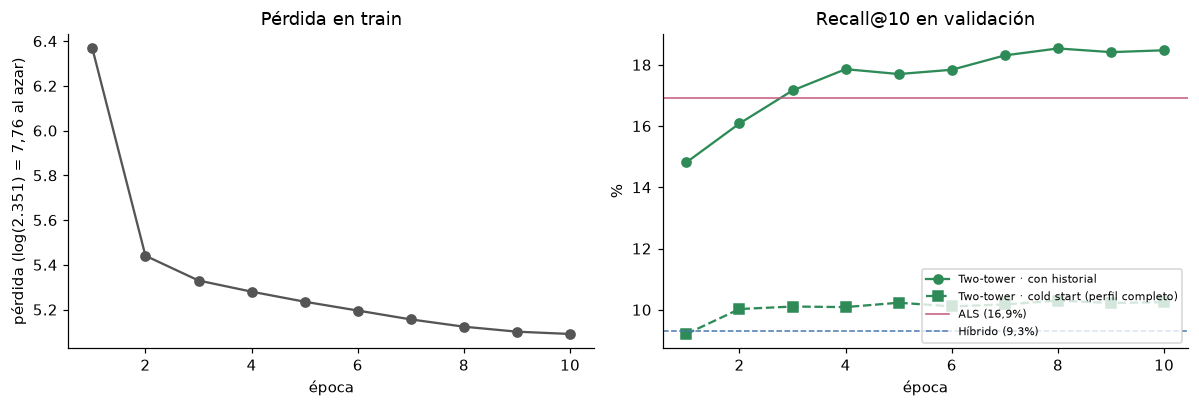

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(tt.log.epoch, tt.log.loss, "o-", color="#555")
ax[0].set(title="Pérdida en train", xlabel="época", ylabel="pérdida (log(2.351) = 7,76 al azar)")
ax[1].plot(tt.log.epoch, tt.log.warm * 100, "o-", color=COLORES["Two-tower"], label="Two-tower · con historial")
ax[1].plot(tt.log.epoch, tt.log.cold_completo * 100, "s--", color=COLORES["Two-tower"], label="Two-tower · cold start (perfil completo)")
ax[1].axhline(16.93, color=COLORES["ALS"], lw=1, label="ALS (16,9%)")
ax[1].axhline(9.31, color=COLORES["Híbrido perfil→ALS"], lw=1, ls="--", label="Híbrido (9,3%)")
ax[1].set(title="Recall@10 en validación", xlabel="época", ylabel="%")
ax[1].legend(fontsize=7.5, loc="lower right")
plt.tight_layout()
plt.savefig(FIG / "03_curvas_entrenamiento.png", bbox_inches="tight")
plt.show()

**Cómo leerlo:** la pérdida baja rápido las primeras 2 épocas y después se aplana. El recall con historial sigue mejorando hasta la época ~7 y ahí se estabiliza; en cold start el modelo llega casi a su techo en la época 3. No hay señales de sobreajuste (el recall de validación no cae al final).

## 5 · Hiperparámetros

Probamos 6 configuraciones con 10 épocas cada una (`scripts/grid_two_tower.py`, ~20 min cada una, por eso no se re-ejecuta acá). Cada fila muestra su mejor época:

In [9]:
grid = pd.read_csv(ROOT / "reports" / "03_two_tower_grid_val.csv")
display(grid.style.format({"recall warm": "{:.2%}", "recall cold (perfil completo)": "{:.2%}", "cobertura cold": "{:.1%}"})
        .highlight_max(subset=["recall warm", "recall cold (perfil completo)"], color="#d8eedf"))

,configuración,mejor época,recall warm,recall cold (perfil completo),cobertura cold
0,"A · base (temp 0,05, hist. dropout 0,3)",9,17.92%,10.18%,2.8%
1,"B · temperatura 0,1",8,17.78%,10.32%,3.3%
2,"C · hist. dropout 0,5",10,17.54%,10.14%,3.1%
3,D · sin hist. dropout,10,18.05%,10.29%,1.7%
4,"E · red más grande (dim 128, hidden 512)",8,18.57%,10.27%,3.1%
5,"F · temperatura 0,02",8,17.59%,10.16%,2.5%


**Qué aprendimos de la grilla:**

- **Todas las configuraciones les ganan a los dos baselines** (ALS 16,9% y híbrido 9,3%). El resultado no depende de haber tenido suerte con un hiperparámetro.
- **La red más grande (E)** es la mejor con historial (18,6%). En cold start, todas quedan entre 10,1% y 10,3%: diferencias de ~0,2 puntos, dentro del ruido. **Elegimos E.**
- **La temperatura** casi no importa entre 0,02 y 0,1.
- **Sorpresa: el *history dropout* no hace falta.** Sin él (D), el cold start es igual de bueno. ¿Por qué? Porque el 58% de las personas de train tiene **un solo** positivo: cuando lo predecimos, su historial (sin ese producto) queda vacío. La red ya practica el cold start "gratis" con la mitad de los datos. Lo único que cambia es la diversidad: sin dropout recomienda menos productos distintos en cold start (1,7% del catálogo contra 2,5–3,3%). Mantuvimos el dropout de 0,3.
- El recall en cold start llega a su techo enseguida (época 3); lo que siguen aprendiendo las épocas siguientes es a usar el historial.

## 6 · El resultado: two-tower contra los baselines

Re-entrenamos los mejores baselines del notebook 02 (con sus hiperparámetros elegidos) para evaluarlos sobre exactamente las mismas personas.

In [10]:
pop = Popularity(s.train, idx)
seg = SegmentPopularity(s.train, s.users, idx, cols=PROFILE_COLS, alpha=100)
als = ALSRecommender(s.train, idx, factors=64, regularization=20, alpha=50)
hib = ProfileToALS(als, s.train, s.users, min_pos=1, ridge_alpha=1000)

res = {
    ("Con historial", "Popularidad"): eval_warm(pop),
    ("Con historial", "ALS"): eval_warm(als),
    ("Con historial", "Two-tower"): eval_warm(tt),
    ("Cold start", "Popularidad"): eval_cold(pop),
    ("Cold start", "Pop. por segmento"): eval_cold(seg),
    ("Cold start", "Híbrido perfil→ALS"): eval_cold(hib),
    ("Cold start", "Two-tower"): eval_cold(tt),
}
# en cold start, la comparación principal es con perfil completo
res_main = {k: (r if k[0] == "Con historial" else r[r.index.isin(completo)]) for k, r in res.items()}

tabla = pd.DataFrame({k: summarize(r, N) for k, r in res_main.items()}).T
tabla.index.names = ["escenario", "modelo"]
tabla.to_csv(ROOT / "reports" / "03_two_tower_val.csv")
print("Cold start = solo personas con perfil completo")
tabla

C:\Users\cande\Universidad Austral\Recomendador Skincare\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\cande\Universidad Austral\Recomendador Skincare\.venv\Lib\site-packages\implicit\cpu\als.py:96: RuntimeWarning: OpenBLAS is configured to use 12 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()


Cold start = solo personas con perfil completo


recall@10  ± recall  ndcg@10  ± ndcg  \
escenario     modelo                                                     
Con historial Popularidad            0.0467    0.0010   0.0249  0.0006   
              ALS                    0.1693    0.0018   0.0972  0.0012   
              Two-tower              0.1853    0.0019   0.1113  0.0013   
Cold start    Popularidad            0.0780    0.0019   0.0525  0.0014   
              Pop. por segmento      0.0920    0.0021   0.0608  0.0014   
              Híbrido perfil→ALS     0.0931    0.0021   0.0600  0.0014   
              Two-tower              0.1030    0.0022   0.0650  0.0015   

                                  cobertura    personas  
escenario     modelo                                     
Con historial Popularidad            0.0094 41,509.0000  
              ALS                    0.4904 41,509.0000  
              Two-tower              0.5160 41,509.0000  
Cold start    Popularidad            0.0043 16,345.0000  
              Pop. por segmento      0.2025 16,345.0000  
              Híbrido perfil→ALS     0.0298 16,345.0000  
              Two-tower              0.0285 16,345.0000

### ¿La diferencia es real o es ruido?

Como todos los modelos se evalúan sobre **las mismas personas**, podemos hacer una comparación **pareada**: para cada persona, restamos el recall de la two-tower menos el del rival, y miramos el promedio de esas diferencias y su error estándar. Es más preciso que comparar dos promedios por separado, porque se cancela que algunas personas son más fáciles que otras para todos los modelos.

In [11]:
def pareada(esc, a, b):
    d = (res_main[(esc, a)].recall - res_main[(esc, b)].recall.reindex(res_main[(esc, a)].index))
    se = d.std() / np.sqrt(len(d))
    return pd.Series({"diferencia (puntos)": d.mean() * 100, "± 95% (puntos)": 1.96 * se * 100,
                      "mejora relativa": d.mean() / res_main[(esc, b)].recall.mean()}, name=f"{a} − {b} ({esc})")

dif = pd.DataFrame([pareada("Con historial", "Two-tower", "ALS"),
                    pareada("Cold start", "Two-tower", "Híbrido perfil→ALS"),
                    pareada("Cold start", "Two-tower", "Pop. por segmento"),
                    pareada("Cold start", "Two-tower", "Popularidad")])
dif.style.format({"diferencia (puntos)": "{:+.2f}", "± 95% (puntos)": "{:.2f}", "mejora relativa": "{:+.1%}"})

,diferencia (puntos),± 95% (puntos),mejora relativa
Two-tower − ALS (Con historial),+1.61,0.33,+9.5%
Two-tower − Híbrido perfil→ALS (Cold start),+0.99,0.31,+10.7%
Two-tower − Pop. por segmento (Cold start),+1.10,0.34,+12.0%
Two-tower − Popularidad (Cold start),+2.50,0.34,+32.0%


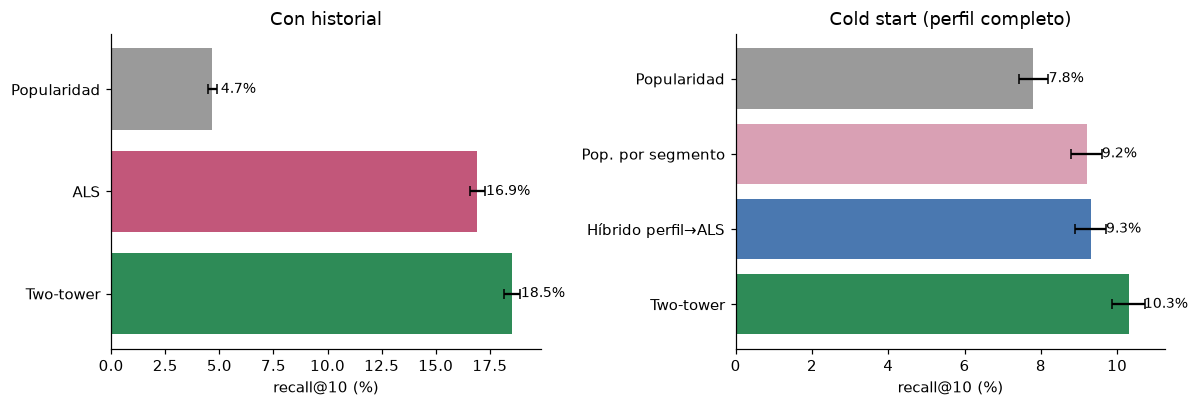

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, esc, titulo in [(axes[0], "Con historial", "Con historial"), (axes[1], "Cold start", "Cold start (perfil completo)")]:
    t = tabla.loc[esc]
    ax.barh(t.index, t["recall@10"] * 100, xerr=1.96 * t["± recall"] * 100,
            color=[COLORES[m] for m in t.index], capsize=3)
    for i, v in enumerate(t["recall@10"] * 100):
        ax.text(v + 0.4, i, f"{v:.1f}%", va="center", fontsize=9)
    ax.set(title=titulo, xlabel="recall@10 (%)")
    ax.invert_yaxis()
plt.tight_layout()
plt.savefig(FIG / "03_two_tower_vs_baselines.png", bbox_inches="tight")
plt.show()

## 7 · Fairness: ¿la red introduce una brecha por tono de piel?

En el notebook 02 los baselines no tenían brecha en contra de los tonos oscuros. La pregunta ahora es si un modelo más complejo, entrenado con datos donde los tonos oscuros son minoría, **aprende peor** para ellos.

In [13]:
filas = []
for (esc, modelo) in [("Con historial", "ALS"), ("Con historial", "Two-tower"),
                      ("Cold start", "Híbrido perfil→ALS"), ("Cold start", "Two-tower")]:
    bt = by_tone(res_main[(esc, modelo)]).assign(escenario=esc, modelo=modelo)
    filas.append(bt.drop(index="desconocido", errors="ignore"))
tono = pd.concat(filas).rename_axis("tone_group").reset_index()

display(tono.pivot_table(index=["escenario", "modelo"], columns="tone_group", values="mean")[TONE_GROUP_ORDER])
display(tono.pivot_table(index=["escenario", "modelo"], columns="tone_group", values="size")[TONE_GROUP_ORDER].astype(int))

tone_group                        claro  light  medio    tan  oscuro
escenario     modelo                                                
Cold start    Híbrido perfil→ALS 0.0966 0.0863 0.0936 0.0934  0.1137
              Two-tower          0.1097 0.0976 0.1003 0.0921  0.1347
Con historial ALS                0.1663 0.1609 0.1760 0.1893  0.1717
              Two-tower          0.1797 0.1773 0.1890 0.1800  0.1962

tone_group                        claro  light  medio   tan  oscuro
escenario     modelo                                               
Cold start    Híbrido perfil→ALS   4740   4407   6006   681     508
              Two-tower            4740   4407   6006   681     508
Con historial ALS                 11513  11704  14446  1289    1101
              Two-tower           11513  11704  14446  1289    1101

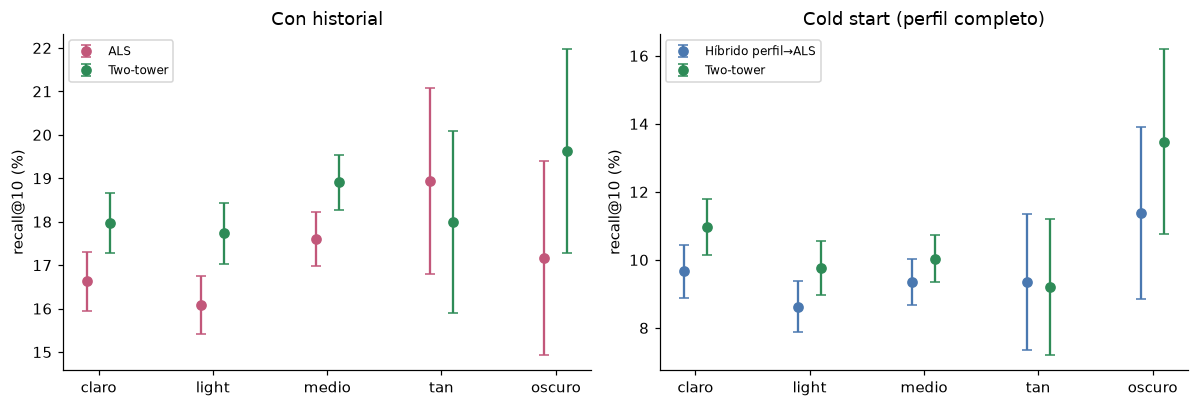

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=False)
x = np.arange(len(TONE_GROUP_ORDER))
for ax, esc, rival in [(axes[0], "Con historial", "ALS"), (axes[1], "Cold start", "Híbrido perfil→ALS")]:
    for j, modelo in enumerate([rival, "Two-tower"]):
        t = tono[(tono.escenario == esc) & (tono.modelo == modelo)].set_index("tone_group").loc[TONE_GROUP_ORDER]
        ax.errorbar(x + (j - 0.5) * 0.2, t["mean"] * 100, yerr=1.96 * t["±"] * 100, fmt="o",
                    color=COLORES[modelo], label=modelo, capsize=3)
    ax.set_xticks(x, TONE_GROUP_ORDER)
    ax.set(title=esc + (" (perfil completo)" if esc == "Cold start" else ""), ylabel="recall@10 (%)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "03_recall_por_tono.png", bbox_inches="tight")
plt.show()

In [15]:
# Brecha = mejor grupo − peor grupo, y cuánto mejora la red a cada grupo respecto de su rival
brecha = tono.groupby(["escenario", "modelo"])["mean"].agg(lambda v: (v.max() - v.min()) * 100).rename("brecha (puntos)")
display(brecha.to_frame())
mejora = (tono.pivot_table(index="tone_group", columns=["escenario", "modelo"], values="mean").loc[TONE_GROUP_ORDER])
mejora = pd.DataFrame({
    "con historial: two-tower − ALS": (mejora[("Con historial", "Two-tower")] - mejora[("Con historial", "ALS")]) * 100,
    "cold start: two-tower − híbrido": (mejora[("Cold start", "Two-tower")] - mejora[("Cold start", "Híbrido perfil→ALS")]) * 100,
})
mejora.style.format("{:+.2f}").set_caption("Mejora de la red por grupo de tono (puntos de recall)")

brecha (puntos)
escenario     modelo                             
Cold start    Híbrido perfil→ALS           2.7448
              Two-tower                    4.2597
Con historial ALS                          2.8409
              Two-tower                    1.8895

,con historial: two-tower − ALS,cold start: two-tower − híbrido
tone_group,,
claro,+1.34,+1.31
light,+1.64,+1.13
medio,+1.31,+0.67
tan,-0.93,-0.13
oscuro,+2.45,+2.10


**Cómo leerlo:**

- **La red no introduce una brecha en contra de los tonos oscuros. Al revés: el grupo *oscuro* es el que más mejora** (+2,5 puntos con historial, +2,1 en cold start). En los dos escenarios, *oscuro* queda como el grupo con mayor recall.
- La "brecha" (mejor grupo − peor grupo) en cold start **sube** de 2,7 a 4,3 puntos, pero no porque algún grupo empeore: es porque *oscuro* mejora mucho más que el resto. *tan* es el único grupo que no mejora (−0,1 y −0,9 puntos).
- **Cautela con los grupos chicos.** *oscuro* tiene 508 personas en cold start y *tan* 681. Con esos tamaños, el margen de error de cada grupo es de ±2,5–3 puntos (al 95%). Las mejoras por grupo, una por una, no son concluyentes; lo que sí es robusto es que **ningún grupo queda claramente peor que con los baselines**.
- *tan* es un grupo a mirar en el paso 4: es el único donde la red no ayuda, y es chico.

Una métrica de brecha "mejor − peor" puede subir por buenas razones (un grupo minoritario que mejora mucho). Por eso conviene mirar siempre la **mejora por grupo** y no solo la brecha.

## 8 · Sesgo de popularidad

¿La red acierta más porque recomienda lo de siempre? Medimos cuántos productos distintos recomienda y qué parte de sus recomendaciones son del **top 2%** de productos más populares (47 productos).

In [16]:
counts = np.bincount(idx.to_pos(s.train.product_id), minlength=N)
top2 = np.argsort(-counts)[: int(0.02 * N)]

def diversidad(r):
    allt = np.concatenate(r.top.to_numpy())
    return pd.Series({"productos distintos": np.unique(allt).size,
                      "cobertura": np.unique(allt).size / N,
                      "% del top 2% popular": np.isin(allt, top2).mean()})

div = pd.DataFrame({k: diversidad(r) for k, r in res_main.items()}).T
div.index.names = ["escenario", "modelo"]
div.style.format({"productos distintos": "{:,.0f}", "cobertura": "{:.1%}", "% del top 2% popular": "{:.0%}"})

**Cómo leerlo:**

- **Con historial**, la red recomienda tantos productos distintos como el ALS (52% del catálogo contra 49%), pero se apoya más en los populares: el 38% de sus recomendaciones son del top 2%, contra el 19% del ALS. Parte de su ventaja viene de "saber cuándo apostar a lo popular".
- **En cold start, el sesgo de popularidad sigue siendo fuerte**: la red recomienda solo 67 productos distintos a 16 mil personas, y el 87% de sus recomendaciones es del top 2%. Es lo mismo que le pasaba al híbrido (70 productos, 82%).

Tiene sentido: con solo 4 datos de perfil, la mejor apuesta suele ser un producto popular. Pero significa que, en cold start, **la red personaliza poco**. Es el punto débil del modelo y algo para atacar en el paso 4 (por ejemplo, penalizando la popularidad al recomendar y midiendo cuánto recall se pierde).

## 9 · ¿Qué aprendió la red?

### Personas inventadas: mismo todo, distinto tipo de piel

Le pedimos recomendaciones a la red para personas **que no existen** (sin historial: cold start puro) que solo difieren en el tipo de piel. Si el perfil importa, las listas deberían cambiar, y los productos deberían "hablar" del tipo de piel.

In [17]:
perfiles = pd.DataFrame([
    {"skin_tone": "light", "skin_type": t, "eye_color": "brown", "hair_color": "brown"}
    for t in ["dry", "oily", "combination", "normal"]
])
sc = tt.score_profiles(perfiles)
tops = np.argsort(-sc, axis=1)[:, :10]
items_i = s.items.reset_index(drop=True)

recs = pd.DataFrame({t: [f"{items_i.product_name[j][:38]} ({items_i.brand_name[j][:14]})" for j in tops[i]]
                     for i, t in enumerate(perfiles.skin_type)})
recs.index = range(1, 11)
display(recs)

,dry,oily,combination,normal
1,Lip Sleeping Mask Intense Hydration wi (LANEIGE),Lip Sleeping Mask Intense Hydration wi (LANEIGE),Lip Sleeping Mask Intense Hydration wi (LANEIGE),Lip Sleeping Mask Intense Hydration wi (LANEIGE)
2,The True Cream Moisturizing Bomb (belif),Niacinamide 10% + Zinc 1% Oil Control (The Ordinary),Alpha Beta Extra Strength Daily Peel P (Dr. Dennis Gro),Alpha Beta Extra Strength Daily Peel P (Dr. Dennis Gro)
3,The True Cream Aqua Bomb (belif),Alpha Beta Extra Strength Daily Peel P (Dr. Dennis Gro),The True Cream Aqua Bomb (belif),The True Cream Aqua Bomb (belif)
4,The Dewy Skin Cream Plumping & Hydrati (Tatcha),The True Cream Aqua Bomb (belif),Niacinamide 10% + Zinc 1% Oil Control (The Ordinary),Protini Polypeptide Firming Refillable (Drunk Elephant)
5,Alpha Beta Extra Strength Daily Peel P (Dr. Dennis Gro),Salicylic Acid Acne Healing Dots (Peace Out),Protini Polypeptide Firming Refillable (Drunk Elephant),Niacinamide 10% + Zinc 1% Oil Control (The Ordinary)
6,Ultra Repair Cream Intense Hydration (First Aid Beau),Protini Polypeptide Firming Refillable (Drunk Elephant),Salicylic Acid Acne Healing Dots (Peace Out),The True Cream Moisturizing Bomb (belif)
7,Protini Polypeptide Firming Refillable (Drunk Elephant),AHA 30% + BHA 2% Exfoliating Peeling S (The Ordinary),Soy Hydrating Gentle Face Cleanser (fresh),Soy Hydrating Gentle Face Cleanser (fresh)
8,Soy Hydrating Gentle Face Cleanser (fresh),Original Skin Matte Moisturizer with W (Origins),The True Cream Moisturizing Bomb (belif),Skinlongevity Long Life Herb Anti-Agin (bareMinerals)
9,Green Clean Makeup Removing Cleansing (Farmacy),Greek Yoghurt Nourishing Probiotic Gel (KORRES),Greek Yoghurt Nourishing Probiotic Gel (KORRES),Salicylic Acid Acne Healing Dots (Peace Out)
10,Hyaluronic Acid 2% + B5 Hydrating Seru (The Ordinary),Green Clean Makeup Meltaway Cleansing (Farmacy),Skinlongevity Long Life Herb Anti-Agin (bareMinerals),C-Rush Vitamin C Gel Moisturizer (OLEHENRIKSEN)


In [18]:
# ¿Los productos recomendados mencionan el tipo de piel? Usamos los highlights de Sephora
# ("Best for Dry, Combo, Normal Skin", "Good for: Dryness", ...)
palabra = {"dry": "Dry", "oily": "Oily", "combination": "Combo", "normal": "Normal"}
high = items_i.highlights.fillna("")
filas = {}
for i, t in enumerate(perfiles.skin_type):
    filas[t] = {f"menciona '{w}'": high.iloc[tops[i]].str.contains(w).mean() for w in palabra.values()}
menciones = pd.DataFrame(filas).T
base = {f"menciona '{w}'": high.str.contains(w).mean() for w in palabra.values()}
menciones.loc["(todo el catálogo)"] = base
display(menciones.style.format("{:.0%}").set_caption("Proporción del top 10 cuyos highlights mencionan cada tipo de piel"))

solap = pd.DataFrame([[len(set(tops[i]) & set(tops[j])) for j in range(4)] for i in range(4)],
                     index=perfiles.skin_type, columns=perfiles.skin_type)
display(solap.style.set_caption("Productos en común entre los top 10 (de 10)"))

,menciona 'Dry',menciona 'Oily',menciona 'Combo',menciona 'Normal'
dry,50%,0%,10%,10%
oily,20%,10%,10%,10%
combination,40%,0%,20%,20%
normal,50%,0%,20%,20%
(todo el catálogo),34%,13%,26%,27%


skin_type,dry,oily,combination,normal
skin_type,,,,
dry,10,4,6,6
oily,4,10,7,6
combination,6,7,10,9
normal,6,6,9,10


**Cómo leerlo:**

- **Las listas cambian con el tipo de piel, y tienen sentido.** A la piel **seca** le recomienda cremas hidratantes (*Moisturizing Bomb*, *Ultra Repair Cream*, *Dewy Skin Cream*, ácido hialurónico). A la piel **grasa**, productos para controlar el sebo y el acné (*Niacinamide + Zinc Oil Control*, ácido salicílico, AHA/BHA, una hidratante *matte*). Nadie le dijo a la red qué significa "oily": lo aprendió de las reseñas.
- **Pero comparten la base.** Los primeros puestos (la *Lip Sleeping Mask*, el peeling de Dr. Dennis Gross, la *Aqua Bomb*) aparecen en todas las listas: son los "favoritos universales". Seca y grasa comparten 4 de 10 productos; mixta y normal, 9 de 10 (son pieles parecidas, y tiene sentido que la red las trate parecido).
- La tabla de highlights es una medida gruesa: la red le da a la piel seca productos que mencionan "Dry" (50%, contra 34% en el catálogo). Para la piel grasa, los highlights no lo reflejan (10%), aunque los nombres de los productos sí lo hacen ("Oil Control", "Matte", "Salicylic"). Muchos productos para piel grasa no tienen el highlight "Best for Oily".

### Mismo tipo de piel, distinto tono

In [19]:
tonos = ["fair", "light", "medium", "tan", "deep", "dark"]
perf_t = pd.DataFrame([{"skin_tone": t, "skin_type": "combination", "eye_color": "brown", "hair_color": "black"} for t in tonos])
tops_t = np.argsort(-tt.score_profiles(perf_t), axis=1)[:, :10]
solap_t = pd.DataFrame([[len(set(a) & set(b)) for b in tops_t] for a in tops_t], index=tonos, columns=tonos)
display(solap_t.style.background_gradient(cmap="RdPu", vmin=0, vmax=10).set_caption("Productos en común entre los top 10 (de 10)"))

solo = {t: [items_i.product_name[j][:40] for j in tops_t[i] if not any(j in tops_t[k] for k in range(len(tonos)) if k != i)]
        for i, t in enumerate(tonos)}
for t, l in solo.items():
    print(f"{t:>7}: solo en su top 10 -> {l if l else '—'}")

,fair,light,medium,tan,deep,dark
fair,10,8,8,7,5,2
light,8,10,6,6,5,1
medium,8,6,10,9,7,2
tan,7,6,9,10,8,1
deep,5,5,7,8,10,2
dark,2,1,2,1,2,10


   fair: solo en su top 10 -> —
  light: solo en su top 10 -> ['Green Clean Makeup Meltaway Cleansing Ba', 'Green Clean Makeup Removing Cleansing Ba']
 medium: solo en su top 10 -> —
    tan: solo en su top 10 -> —
   deep: solo en su top 10 -> ['Daily Microfoliant Exfoliator']
   dark: solo en su top 10 -> ['Vinopure Natural Salicylic Acid Pore Min', 'Squalane + Vitamin C Rose Firming Oil', 'Vinosource-Hydra Moisturizing Sorbet', 'Sugar Hydrating Lip Balm', 'Beauty Elixir Prep, Set, Glow Face Mist', 'Secret Sauce Moisturizer', 'Greek Yoghurt Probiotic Superdose Face M']


**Cómo leerlo:**

- Los tonos vecinos comparten casi toda la lista (fair–light 8 de 10, medium–tan 9 de 10), y los tonos más alejados comparten menos (fair–deep 5 de 10). La red aprendió un **orden** entre los tonos sin que nadie se lo dijera: para ella, cada tono es solo una categoría más.
- **El tono *dark* es la excepción: su lista es casi completamente distinta** (comparte 1–2 productos con el resto). *dark* es uno de los tonos más chicos del dataset (unas 500 reseñas). Con tan pocos datos, su embedding está poco estimado y la red "inventa" más.

Esto puede ser bueno (recomendaciones realmente personalizadas) o malo (ruido). Es una pregunta de *fairness* interesante para el paso 4: ¿la red recomienda distinto a los grupos chicos porque aprendió algo o porque sabe poco? Una forma de verlo: medir el recall de las personas *dark* específicamente, o reentrenar con distintas semillas y ver si su lista se mantiene estable.

### Productos "vecinos" en el mapa de la red

La torre producto ubica cada producto en un espacio de 128 dimensiones. Productos cercanos son productos que la red considera intercambiables (les gustan a las mismas personas, o comparten ingredientes, marca, categoría). Miramos los 5 vecinos más cercanos de algunos productos populares:

In [20]:
V = tt.item_vectors().numpy()
sim = V @ V.T
populares = np.argsort(-counts)[[0, 5, 20]]
for j in populares:
    vec = np.argsort(-sim[j])[1:6]
    print(f"\n{items_i.product_name[j]} ({items_i.brand_name[j]}, {items_i.secondary_category[j]}):")
    for v in vec:
        print(f"   {sim[j, v]:.2f}  {items_i.product_name[v][:50]} ({items_i.brand_name[v]}, {items_i.secondary_category[v]})")


Lip Sleeping Mask Intense Hydration with Vitamin C (LANEIGE, Lip Balms & Treatments):
   0.95  Lip Glowy Balm (LANEIGE, Lip Balms & Treatments)
   0.90  The Dewy Skin Cream Plumping & Hydrating Moisturiz (Tatcha, Moisturizers)
   0.90  Cleansing & Exfoliating Wipes (SEPHORA COLLECTION, Cleansers)
   0.90  Sugar Hydrating Lip Balm (fresh, Lip Balms & Treatments)
   0.90  Glow2OH Dark Spot Toner (OLEHENRIKSEN, Cleansers)

The True Cream Aqua Bomb (belif, Moisturizers):
   0.93  The True Cream Moisturizing Bomb (belif, Moisturizers)
   0.90  Moisturizing Eye Bomb with Squalane (belif, Eye Care)
   0.89  Greek Yoghurt Foaming Cream Cleanser (KORRES, Cleansers)
   0.87  Lip Sleeping Mask Intense Hydration with Vitamin C (LANEIGE, Lip Balms & Treatments)
   0.87  Soy Hydrating Gentle Face Cleanser (fresh, Cleansers)

Daily Microfoliant Exfoliator (Dermalogica, Cleansers):
   0.75  Precleanse Cleansing Oil (Dermalogica, Cleansers)
   0.70  Watermelon Glow PHA + BHA Pore-Tight Toner (Glow Rec

## 10 · Conclusiones

### El resultado principal (validación)

| Escenario | Mejor baseline | Two-tower | Diferencia (pareada, ±95%) | Mejora relativa |
|---|---|---|---|---|
| **Con historial** | ALS: 16,9% | **18,5%** | +1,6 ± 0,3 puntos | +9,5% |
| **Cold start** (perfil completo) | Híbrido: 9,3% · Pop. por segmento: 9,2% | **10,3%** | +1,0 ± 0,3 puntos | +10,7% |

**La red les gana a todos los baselines en los dos escenarios, y las diferencias son claramente significativas.** También mejora el NDCG (acierta más arriba en la lista): 0,111 contra 0,097 del ALS.

### Lo que aprendimos

**1. Un solo modelo para los dos escenarios.** ALS solo sirve con historial y el híbrido solo en cold start. La red hace las dos cosas, y mejor. Además, puede recomendar productos nuevos (por sus ingredientes, marca y categoría) que ningún baseline puede manejar.

**2. Las ganancias son reales, pero moderadas.** +10% relativo en cada escenario. En cold start, pasar de "lo más popular" (7,8%) a la red (10,3%) es una mejora del 32%: el perfil de piel sí ayuda, pero 4 datos de perfil no alcanzan para personalizar mucho.

**3. La red no introduce una brecha en contra de los tonos oscuros.** El grupo *oscuro* es el que más mejora (+2,1 a +2,5 puntos) y queda como el de mayor recall. Ningún grupo empeora claramente; *tan* es el único que no mejora. Los grupos chicos tienen márgenes de error grandes (±2,5–3 puntos), así que estas diferencias por grupo son indicios, no conclusiones.

**4. En cold start, el sesgo de popularidad es fuerte.** La red recomienda solo 67 productos distintos a 16 mil personas nuevas (el 87% del top 2% más popular). Personaliza, y las listas tienen sentido (hidratantes para piel seca, control de sebo para piel grasa), pero sobre una base de "favoritos universales".

**5. La red aprendió cosas que nadie le enseñó:** que *oily* necesita control de sebo, que los tonos tienen un orden, que los productos de la misma línea son intercambiables (*Aqua Bomb* ↔ *Moisturizing Bomb*).

**6. El *history dropout* no hacía falta.** El 58% de las personas tiene un solo positivo, así que la red ya practica el cold start "gratis".

### Lo que queda abierto para el paso 4

- **Ablaciones**: ¿cuánto aporta cada pieza? Sin perfil, sin ingredientes, sin highlights, sin historial. La red ya tiene los interruptores (`use_profile`, `use_content`, `use_history`, `use_item_id`).
- **Fairness**: ¿por qué el tono *dark* recibe una lista tan distinta? ¿Por qué *tan* no mejora?
- **Popularidad**: ¿cuánto recall se pierde si penalizamos lo popular para diversificar el cold start?
- **Test**: evaluar todos los modelos **una sola vez** en test, al final.

El modelo entrenado quedó guardado en `models/two_tower.pt` (no se sube a git).